## 地面基站功率放大器分析

### 线圈基本电气特性

In [19]:
import numpy as np
from magcomm.const import Const
from magcomm.coil import *
import matplotlib.pyplot as plt

tx_coil = OGCoil(
    real_line = True,
    line_radius = 1.5e-3 / 2,
    frequency = 4e3
)
print(f"线圈的电阻: {tx_coil.resistance:.4f} Ω")
print(f"线圈的电感: {tx_coil.inductance:.4f} H")
print(f"线圈电感有效： {tx_coil.inductance_valid}")

# 校正线圈的电感为3.67mH
inductance = 3.67e-3
tx_coil.inductance = inductance
print(f"谐振电容: {tx_coil.calculate_resonant_capacitor():.4e} F")
print(f"谐振电压: {tx_coil.calculate_resonant_voltage():.4f} V")
print(f"Q值: {2 * np.pi * tx_coil.inductance * tx_coil.frequency / tx_coil.resistance:.4f}")

线圈的电阻: 1.5262 Ω
线圈的电感: 0.2577 H
线圈电感有效： False
谐振电容: 4.3137e-07 F
谐振电压: 922.3716 V
Q值: 60.4365


### 频率特性分析

线圈采用串联谐振的方法降低等效输入阻抗，假定线圈电感为3.67mH，不考虑寄生电容，使用外部431nF进行谐振。线圈总阻抗设定为2Ω，则阻抗和电流随频率的关系为：

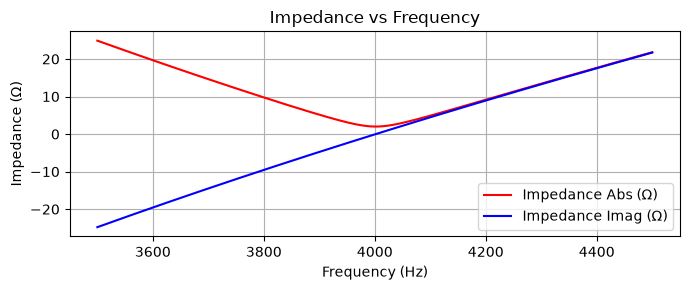

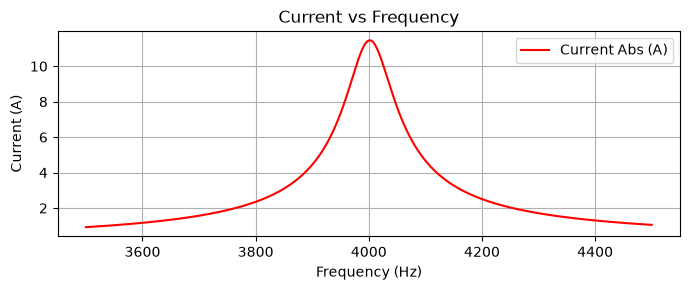

In [20]:
frequency = np.linspace(3.5e3, 4.5e3, 1000)
omega = 2 * np.pi * frequency
inductance = 3.67e-3
resistance = 2
capacitance = 431e-9

impedance = resistance + 1j * (omega * inductance - 1 / (omega * capacitance))
voltage_dc = 18
voltage = 4 * voltage_dc / np.pi
current = voltage / impedance

plt.figure(figsize=(7, 3))
plt.plot(frequency, np.abs(impedance), label='Impedance Abs (Ω)', color='r')
plt.plot(frequency, np.imag(impedance), label='Impedance Imag (Ω)', color='b')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Impedance (Ω)')
plt.title('Impedance vs Frequency')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3))
plt.plot(frequency, np.abs(current), label='Current Abs (A)', color='r')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Current (A)')
plt.title('Current vs Frequency')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 电容范围分析

实际的电容有10%的误差，因此需要分析在电容变化时的电流情况，而系统电压可以放宽到24V，要求满足10A的峰值电流要求。

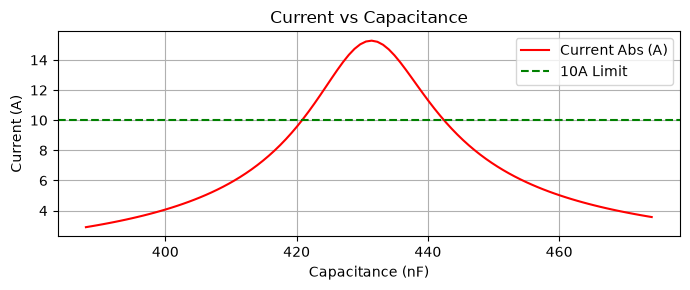

In [21]:
capacitance_values = np.linspace(0.9 * capacitance, 1.1 * capacitance, 100)
omega = 2 * np.pi * 4e3
impedance_values = resistance + 1j * (omega * inductance - 1 / (omega * capacitance_values))
voltage_dc = 24
voltage = 4 * voltage_dc / np.pi
current_values = voltage / impedance_values

plt.figure(figsize=(7, 3))
plt.plot(capacitance_values * 1e9, np.abs(current_values), label='Current Abs (A)', color='r')
plt.xlabel('Capacitance (nF)')
plt.ylabel('Current (A)')
plt.title('Current vs Capacitance')
plt.axhline(y=10, color='g', linestyle='--', label='10A Limit')
plt.grid(True)
plt.tight_layout()
plt.legend()

### 实际电路设计

地面功率放大器使用全桥Class-D结构进行设计，基本的设计结构如下图所示：

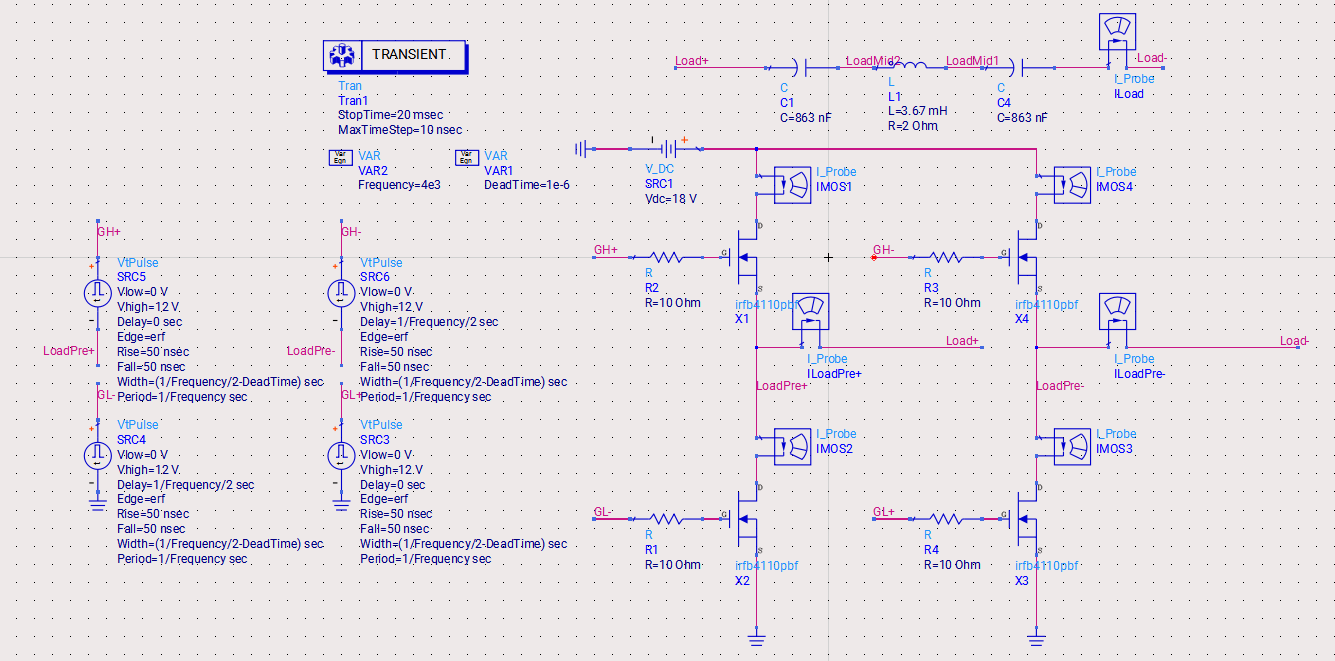

仿真为Transient仿真，0~10ms，主频率为4kHz，MOS驱动死区为1us。以下提取.dat仿真结果

In [22]:
import pickle
import os
import subprocess
import ipynbname
import pprint
import numpy as np
from scipy.integrate import trapezoid

ds_path = "C:/Users/YangHui/Documents/ADS/MagnetWirelessCommunication/data/tx_pa.ds"

output_file_name = 'tx_pa'
script_path = ipynbname.path().parent
out_path = os.path.join(script_path, "..", "..", "out", f'{output_file_name}.pkl')

if not os.path.exists(out_path):
    # 在对应目录下执行bat脚本提取数据
    run_path = os.path.join(script_path, "..", "..")
    subprocess.run([os.path.join(run_path, "run_export_ds.bat"), ds_path], cwd=run_path, shell=True)

data = pickle.load(open(out_path, 'rb'))
pprint.pprint(data['Tran1.TRAN'].keys())

# 4kHz的频率意味着每ms会有4个周期，因此只需要计算整数ms内的平均功率即可
sim_tran = data['Tran1.TRAN']
time = sim_tran['time']
sim_time = [0, 60e-3]
idx = np.where((time >= sim_time[0]) & (time <= sim_time[1]))[0]
time = time[idx]

dict_keys(['time', 'LoadPre-', 'LoadPre+', 'LoadMid2', 'LoadMid1', 'Load+', 'GL-', 'GH+', 'GH-', 'GL+', 'Load-', 'Vsrc', 'Vdc', 'SRC3.SRC.i', 'SRC5.SRC.i', 'SRC2.SRC.i', 'SRC4.SRC.i', 'SRC1.i', 'X2.vfi1.i', 'X2.vfi2.i', 'X1.vfi1.i', 'X1.vfi2.i', 'X4.vfi1.i', 'X4.vfi2.i', 'X3.vfi1.i', 'X3.vfi2.i', 'Idc.i', 'ILoadPre-.i', 'ILoadPre+.i', 'IMOS3.i', 'IMOS2.i', 'IMOS4.i', 'IMOS1.i', 'ILoad.i', 'tranorder'])


### 线圈加载电流

计算在该电压下，线圈上产生的电流的有效值RMS：

In [23]:
current = sim_tran['ILoad.i'][idx]
current_rms = np.sqrt(np.mean(current**2))
print(f"线圈加载电流的有效值RMS: {current_rms:.4f} A")
print(f"线圈加载电流的峰值: {np.max(current):.4f} A")

线圈加载电流的有效值RMS: 6.7096 A
线圈加载电流的峰值: 12.5747 A


当前电流满足线圈10A的峰值电流要求

### 耐压分析

计算线圈两端和电容两端的电压峰值：

In [24]:
voltage_coil = sim_tran['LoadMid1'][idx] - sim_tran['LoadMid2'][idx]
voltage_coil_peak = np.max(np.abs(voltage_coil))
voltage_cap = sim_tran['LoadMid1'][idx] - sim_tran['LoadPre+'][idx]
voltage_cap_peak = np.max(np.abs(voltage_cap))
print(f"线圈两端电压峰值: {voltage_coil_peak:.4f} V")
print(f"电容两端电压峰值: {voltage_cap_peak:.4f} V")

线圈两端电压峰值: 1190.1644 V
电容两端电压峰值: 624.0917 V


### D类放大器效率分析

放大器效率为一段时间内电源的输出功率和输入功率的比值。我们将主要考虑MOS管上的功率损耗。

In [25]:
from pa.power import *
voltage_dc = 18

# 系统的总输出功率
print(f"系统总输出功率: {calculate_power(
    voltage=sim_tran['Vdc'][idx],
    current=np.array(sim_tran['IMOS1.i'][idx]) + np.array(sim_tran['IMOS4.i'][idx]) ,
    time=time
):.2f} W")

# 分别计算四个MOS管上的功率损耗
# MOS1
print(f"单个MOS的功率损耗：{calculate_power(
    voltage=np.array(sim_tran['Vdc'][idx]) - np.array(sim_tran['LoadPre+'][idx]),
    current=np.array(sim_tran['IMOS1.i'][idx]),
    time=time
):.2f} W")

# 线圈加载功率
print(f"线圈加载功率: {calculate_power(
    voltage=np.array(sim_tran['Load+'][idx]) - np.array(sim_tran['Load-'][idx]),
    current=np.array(sim_tran['ILoad.i'][idx]),
    time=time
):.2f} W")

系统总输出功率: 90.26 W
单个MOS的功率损耗：1.03 W
线圈加载功率: 87.36 W


### 波形分析

首先分析线圈的电流的BPSK特性，具体方法为对其进行4kHz的正交下变频然后分析其相位。

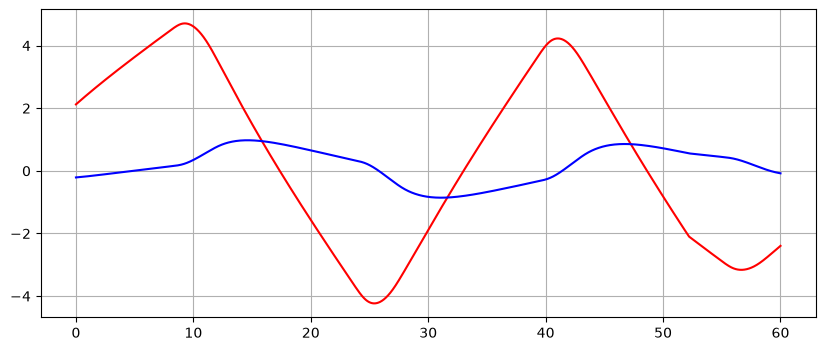

In [47]:
# 绘制ILoad.i的STFT图像
from pa.lpf import *
from pa.resample import *

time
current_load = sim_tran['ILoad.i'][idx]

carrier_frequency = 4e3
carrier = np.exp(-1j * (2 * np.pi * carrier_frequency * time - np.pi * 0.38))
current_load_demodulated = current_load * carrier

current_load_demodulated, new_timestamp = resample_signal(current_load_demodulated, time, 64e3)
current_load_demodulated = fir_lowpass_filter(current_load_demodulated, 100, 64e3, 101)

# plt.figure(figsize=(10, 4))
# plt.plot(new_timestamp * 1e3, np.unwrap(np.angle(current_load_demodulated)), label='Demodulated Current (Real)', color='b')
# plt.plot(new_timestamp * 1e3, np.abs(current_load_demodulated), label='Demodulated Current (Magnitude)', color='r')
# plt.grid(True)
# plt.show()

# 以64e3的采样率，生成一个1000长度的FIR滤波器作为匹配滤波器
match_filter = np.ones(1000) / 1000
matched_output = np.convolve(current_load_demodulated, match_filter, mode='same')

plt.figure(figsize=(10, 4))
plt.plot(new_timestamp * 1e3, np.real(matched_output), label='Matched Filter Output (Magnitude)', color='r')
plt.plot(new_timestamp * 1e3, np.imag(matched_output), label='Matched Filter Output (Magnitude)', color='b')
plt.grid(True)
plt.show()